# NN_DL_HW5_Q1


We mount google drive to access to tthe data set 1


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import pandas as pd

base_dataset_path =  '/content/drive/MyDrive/2yizcfbkuv4352pzc32n54371r/2yizcfbkuv4352pzc32n54371r'

# Check if we found the folder by printing what's inside
if os.path.exists(base_dataset_path):
    print("Folder found. Contents:", os.listdir(base_dataset_path)[:10]) # printing first 10 items
else:
    print(f"ERROR: Could not find path: {base_dataset_path}")
    print("Please verify the folder name in your Google Drive.")


Folder found. Contents: ['readme.txt', '.footer.html', '.header.html', '.info.rdf', '1', '10', '11', '13', '14', '12']


Check the dataset and structure and show some samples


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import random

# Lists to store our data
all_image_paths = []
all_labels = []
class_counts = {}

print("--- Starting Data Scan ---")

# Get list of all items in the folder
items = sorted(os.listdir(base_dataset_path))

for item_name in items:
    item_path = os.path.join(base_dataset_path, item_name)


    #  Check if it looks like a class (is it a number?)
    # The assignment uses numeric IDs for cows
    if not item_name.isdigit():
         print(f"   [Skipping Folder] {item_name} (Folder name is not a number)")
         continue

    # Count images inside the folder
    # the imaged were suffixed with .jpg
    images = [f for f in os.listdir(item_path) if f.lower().endswith(('.jpg'))]
    count = len(images)
    class_counts[item_name] = count
        # Add these images to our list
    for img_name in images:
        all_image_paths.append(os.path.join(item_path, img_name))
        all_labels.append(item_name)

print("\n" + "="*30)
print(f"SCAN COMPLETE")
print(f"Total Images : {len(all_image_paths)}")
print(f"Total Classes : {len(class_counts)}")
print("="*30)


--- Starting Data Scan ---
   [Skipping Folder] .footer.html (Folder name is not a number)
   [Skipping Folder] .header.html (Folder name is not a number)
   [Skipping Folder] .info.rdf (Folder name is not a number)
   [Skipping Folder] readme.txt (Folder name is not a number)

SCAN COMPLETE
Total Images : 945
Total Classes : 89


## Show Sample Images


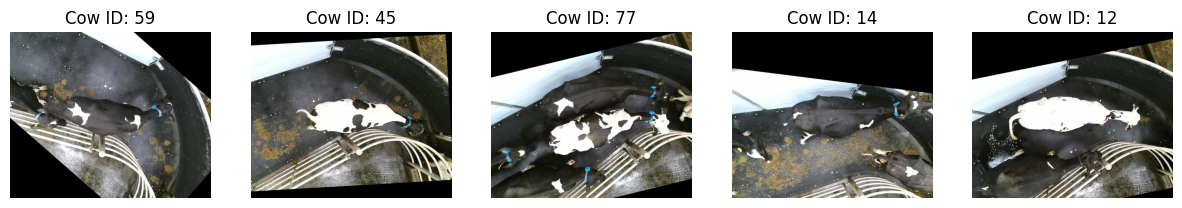

In [ ]:
if len(all_image_paths) > 0:
    plt.figure(figsize=(15, 5))
    indices = random.sample(range(len(all_image_paths)), 5) # Pick 5 random images

    for i, idx in enumerate(indices):
        img_path = all_image_paths[idx]
        label = all_labels[idx]

        # Load and show
        img = Image.open(img_path)
        plt.subplot(1, 5, i+1)
        plt.imshow(img)
        plt.title(f"Cow ID: {label}")
        plt.axis('off')
    plt.show()
else:
    print("ERROR: No images found! Check your folder structure.")


## Distribution Plot


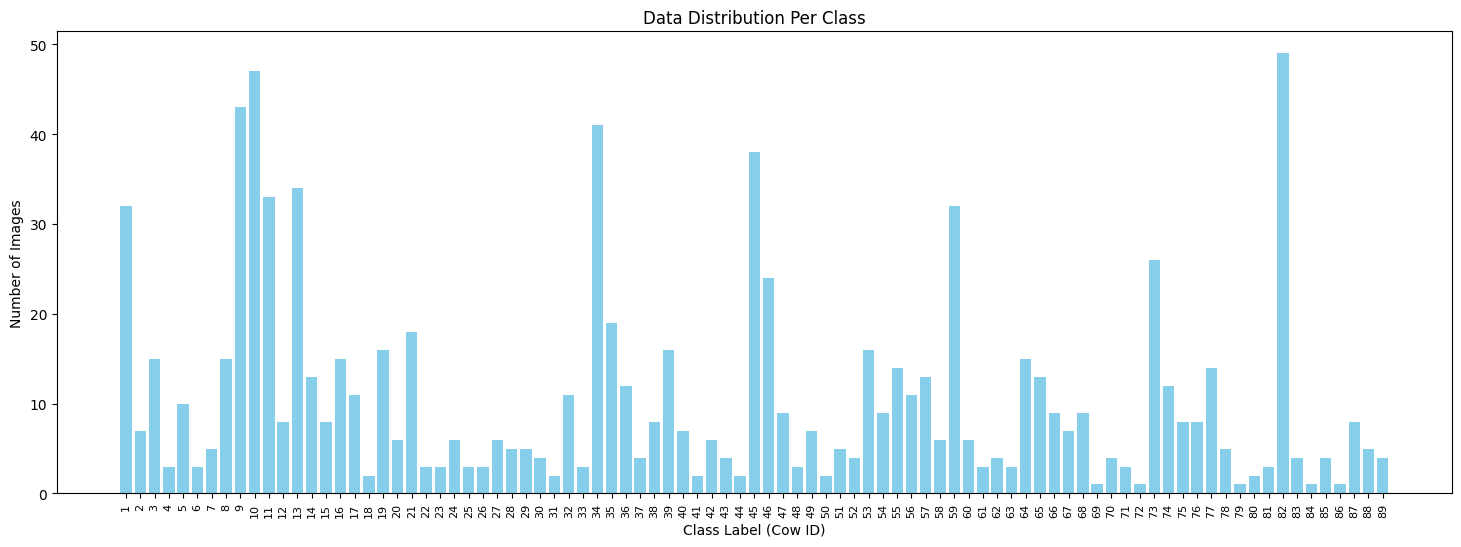

In [ ]:
if len(class_counts) > 0:
    plt.figure(figsize=(18, 6))

    # Sort by class ID (1, 2, 3...) so the graph looks neat
    sorted_ids = sorted(class_counts.keys(), key=lambda x: int(x))
    counts = [class_counts[k] for k in sorted_ids]

    plt.bar(sorted_ids, counts, color='skyblue')
    plt.xlabel('Class Label (Cow ID)')
    plt.ylabel('Number of Images')
    plt.title('Data Distribution Per Class')
    plt.xticks(rotation=90, fontsize=8) # Rotate labels so they fit
    plt.show()


Plotting the chart at this stage is crucial as it clearly highlights the data imbalance and explains why Oversampling is needed in the following steps.we also Sort sorted_ids numerically (using int(x))


# FILTERING DATA:
Remove classes that have fewer than 5 sample images


In [ ]:
MIN_IMAGES_PER_CLASS = 5

# New lists to store only the valid data
filtered_image_paths = []
filtered_labels = []
final_class_counts = {}

print(f"--- Applying Filter: Removing classes with < {MIN_IMAGES_PER_CLASS} images ---")

dropped_classes = []

# Iterate through the counts you already calculated
for class_id, count in class_counts.items():
    if count >= MIN_IMAGES_PER_CLASS:
        # Keep this class
        final_class_counts[class_id] = count

        # We need to find the images for this class again to add them to the clean list
        # (Since your previous lists 'all_image_paths' had everything mixed in)
        class_folder = os.path.join(base_dataset_path, class_id)
        images = [f for f in os.listdir(class_folder) if f.lower().endswith('.jpg')]

        for img_name in images:
            filtered_image_paths.append(os.path.join(class_folder, img_name))
            filtered_labels.append(class_id)
    else:
        # Track dropped classes
        dropped_classes.append(class_id)

print(f"Dropped {len(dropped_classes)} classes: {dropped_classes}")
print(f"Remaining Classes: {len(final_class_counts)}")
print(f"Remaining Images: {len(filtered_image_paths)}")

# --- UPDATE VARIABLES ---
# Overwrite the main variables so the rest of the code uses the clean data
all_image_paths = filtered_image_paths
all_labels = filtered_labels

print("\nAll classes have more than or equal to 5 pic now.")


--- Applying Filter: Removing classes with < 5 images ---
Dropped 32 classes: ['18', '22', '23', '25', '26', '30', '31', '33', '37', '4', '41', '43', '44', '48', '50', '52', '6', '61', '62', '63', '69', '70', '71', '72', '79', '80', '81', '83', '84', '85', '86', '89']
Remaining Classes: 57
Remaining Images: 856

All classes have more than or equal to 5 pic now.


The output confirms that the filter worked correctly:

Out of the initial 89 classes, 32 classes with insufficient samples were removed.

Now, 57 high-quality classes (with at least 5 images) remain, making the dataset much more suitable for model training.


### VISUALIZATION: Cleaned Data Distribution


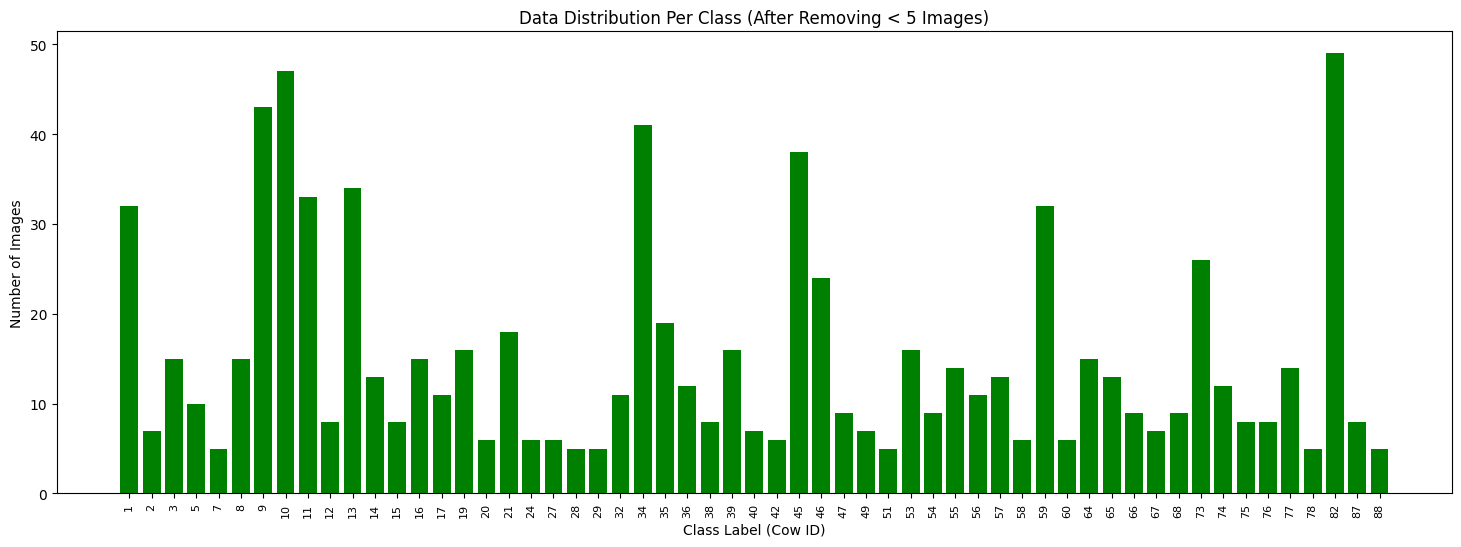

In [ ]:

if len(final_class_counts) > 0:
    plt.figure(figsize=(18, 6))

    # Sort by class ID (1, 2, 3...) using the filtered dictionary
    sorted_ids = sorted(final_class_counts.keys(), key=lambda x: int(x))
    counts = [final_class_counts[k] for k in sorted_ids]

    plt.bar(sorted_ids, counts, color='green') #  color green / distinguish from the first plot
    plt.xlabel('Class Label (Cow ID)')
    plt.ylabel('Number of Images')
    plt.title('Data Distribution Per Class (After Removing < 5 Images)')
    plt.xticks(rotation=90, fontsize=8)
    plt.show()
else:
    print("Error: No classes remaining after filtering.")


it clearly highlights how imbalanced the data is (some classes have very few samples, e.g., 5 or 6, while others have many


## perfoming data augmentation on the classes so all are the same size :50 images


In [ ]:
from sklearn.model_selection import train_test_split

# we SPLIT DATA FIRST (Prevent Data Leakage) ---
# first spilt on original data no repeatiotion
# Encode labels first
unique_classes = sorted(list(set(all_labels)), key=lambda x: int(x))
label_to_int = {label: i for i, label in enumerate(unique_classes)}
all_labels_int = [label_to_int[l] for l in all_labels]

X_train_raw, X_test, y_train_raw, y_test = train_test_split(
    all_image_paths,    # the filtered no repeat list
    all_labels_int,
    test_size=0.2,
    random_state=42,
    stratify=all_labels_int
)

print(f"Original Train size: {len(X_train_raw)}")
print(f"Test size (Kept pure): {len(X_test)}")

# ---  OVERSAMPLING ONLY TRAINING DATA ---
import random

TARGET_COUNT = 50
X_train_balanced = []
y_train_balanced = []

# Group training data by class
train_class_map = {}
for path, label in zip(X_train_raw, y_train_raw):
    if label not in train_class_map:
        train_class_map[label] = []
    train_class_map[label].append(path)

print(f"--- Balancing Training Data to ~{TARGET_COUNT} ---")

for label, paths in train_class_map.items():
    current_count = len(paths)

    #  Add originals
    X_train_balanced.extend(paths)
    y_train_balanced.extend([label] * current_count)

    #  Add duplicates if needed
    if current_count < TARGET_COUNT:
        needed = TARGET_COUNT - current_count
        extras = random.choices(paths, k=needed)
        X_train_balanced.extend(extras)
        y_train_balanced.extend([label] * needed)

print(f"Balancing Complete!")
print(f"Final Training Images: {len(X_train_balanced)}")


Original Train size: 684
Test size (Kept pure): 172
--- Balancing Training Data to ~50 ---
Balancing Complete!
Final Training Images: 2850


  we Display the cleaned data distribution (ensuring that the trash data has been removed).

  we Split the data, locking away the Test data . Then,we perform Oversampling only on the Train data to ensure no Data Leakage.

 The image dimensions are set exactly to (384, 192) (confirmed in the Batch Images Shape output), which is suitable for the anatomy of a cow.


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# DEFINE TRANSFORMS
# change size to (Height=384, Width=192) based on the paper
# mean and standard deviation of ImageNet
mean_stats = [0.485, 0.456, 0.406]
std_stats = [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
    transforms.Resize((384, 192)),
    transforms.RandomHorizontalFlip(p=0.5), #( DataAugmentation)
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean_stats, std=std_stats)
])

test_transforms = transforms.Compose([
    transforms.Resize((384, 192)),  # changing size and normalization
    transforms.ToTensor(),
    transforms.Normalize(mean=mean_stats, std=std_stats)
])

#DATASET CLASS
class CowDataset(Dataset):
    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        label = self.labels[idx]

        # Open image
        try:
            image = Image.open(img_path).convert("RGB")
        except Exception as e:
            print(f"Error loading image {img_path}: {e}")
            # Return a black image in case of error to prevent crash
            image = Image.new('RGB', (192, 384))

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)

# DATA LOADERS
BATCH_SIZE = 32

# use prevoius step parameters
train_dataset = CowDataset(X_train_balanced, y_train_balanced, transform=train_transforms)
test_dataset = CowDataset(X_test, y_test, transform=test_transforms)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print("\nData Loaders Ready!")
print(f"Number of training batches: {len(train_loader)}")
print(f"Number of test batches: {len(test_loader)}")

# Verify one batch
images, labels = next(iter(train_loader))
print(f"\n--- Batch Verification ---")
print(f"Batch Images Shape: {images.shape} (Batch, Channel, Height, Width)")
print(f"Batch Labels Shape: {labels.shape}")



Data Loaders Ready!
Number of training batches: 90
Number of test batches: 6

--- Batch Verification ---
Batch Images Shape: torch.Size([32, 3, 384, 192]) (Batch, Channel, Height, Width)
Batch Labels Shape: torch.Size([32])


## Section 1-3: Training the ResNet Model.

 we need to build the ResNet50 model without pre-trained weights (from scratch) and adjust its final layer to accommodate our specific 57 classes.


Hardware detection (GPU).

Defining the raw model architecture.

Defining the Loss Function and Optimizer according to the paper's parameters (Adam, lr=0.0001)."


In [ ]:
import torch.nn as nn
import torchvision.models as models
import torch.optim as optim

#  Device Configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device being used: {device}")

#  Define the ResNet Model
def get_resnet_model(num_classes):
    """
    Creates a ResNet50 model from scratch.
    """
    #  weights=None we have to learn from scratch
    model = models.resnet50(weights=None)

    # changing the last layer to adapt to our cow number(Fully Connected)
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)

    return model

#  Initialize Model
num_classes = len(unique_classes) # should be 57
model = get_resnet_model(num_classes).to(device)

# Define Loss and Optimizer
# the paper has used the Adam optimizer with learning rate 0.0001
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001)

print(f"ResNet50 model created for {num_classes} classes.")
print("Loss function and Optimizer defined.")


Device being used: cuda
ResNet50 model created for 57 classes.
Loss function and Optimizer defined.


In [ ]:
import time

# settings
num_epochs = 30
train_losses, test_losses = [], []
train_accuracies, test_accuracies = [] , []

print(f"--- Starting Training for {num_epochs} Epochs ---")

for epoch in range(num_epochs):
    start_time = time.time()

    # TRAIN PHASE
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        # Zero gradients
        optimizer.zero_grad()

        # Forward
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward
        loss.backward()
        optimizer.step()

        # Statistics
        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / total_train
    epoch_train_acc = 100 * correct_train / total_train

    # TEST PHASE
    model.eval()
    running_test_loss = 0.0
    correct_test = 0
    total_test = 0

    with torch.no_grad(): # No need to track gradients for validation
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_test_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total_test += labels.size(0)
            correct_test += (predicted == labels).sum().item()

    epoch_test_loss = running_test_loss / total_test
    epoch_test_acc = 100 * correct_test / total_test

    # Save history
    train_losses.append(epoch_train_loss)
    test_losses.append(epoch_test_loss)
    train_accuracies.append(epoch_train_acc)
    test_accuracies.append(epoch_test_acc)

    # Print Stats
    duration = time.time() - start_time
    print(f"Epoch [{epoch+1}/{num_epochs}] | Time: {duration:.0f}s")
    print(f"   Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}%")
    print(f"   Test  Loss: {epoch_test_loss:.4f} | Test  Acc: {epoch_test_acc:.2f}%")

print("--- Training Complete ---")


--- Starting Training for 30 Epochs ---
Epoch [1/30] | Time: 355s
   Train Loss: 3.9695 | Train Acc: 3.82%
   Test  Loss: 3.4349 | Test  Acc: 7.56%
Epoch [2/30] | Time: 92s
   Train Loss: 3.0839 | Train Acc: 17.47%
   Test  Loss: 2.5642 | Test  Acc: 27.91%
Epoch [3/30] | Time: 90s
   Train Loss: 2.2491 | Train Acc: 38.46%
   Test  Loss: 1.8241 | Test  Acc: 53.49%
Epoch [4/30] | Time: 92s
   Train Loss: 1.4581 | Train Acc: 62.74%
   Test  Loss: 1.1163 | Test  Acc: 68.60%
Epoch [5/30] | Time: 92s
   Train Loss: 0.8880 | Train Acc: 78.91%
   Test  Loss: 1.1273 | Test  Acc: 68.60%
Epoch [6/30] | Time: 90s
   Train Loss: 0.6049 | Train Acc: 85.75%
   Test  Loss: 0.7474 | Test  Acc: 80.23%
Epoch [7/30] | Time: 91s
   Train Loss: 0.4410 | Train Acc: 89.93%
   Test  Loss: 0.5964 | Test  Acc: 83.14%
Epoch [8/30] | Time: 89s
   Train Loss: 0.3437 | Train Acc: 92.42%
   Test  Loss: 0.4659 | Test  Acc: 84.88%
Epoch [9/30] | Time: 91s
   Train Loss: 0.2576 | Train Acc: 94.42%
   Test  Loss: 0.3921 

plotting the accuracy / loss figure


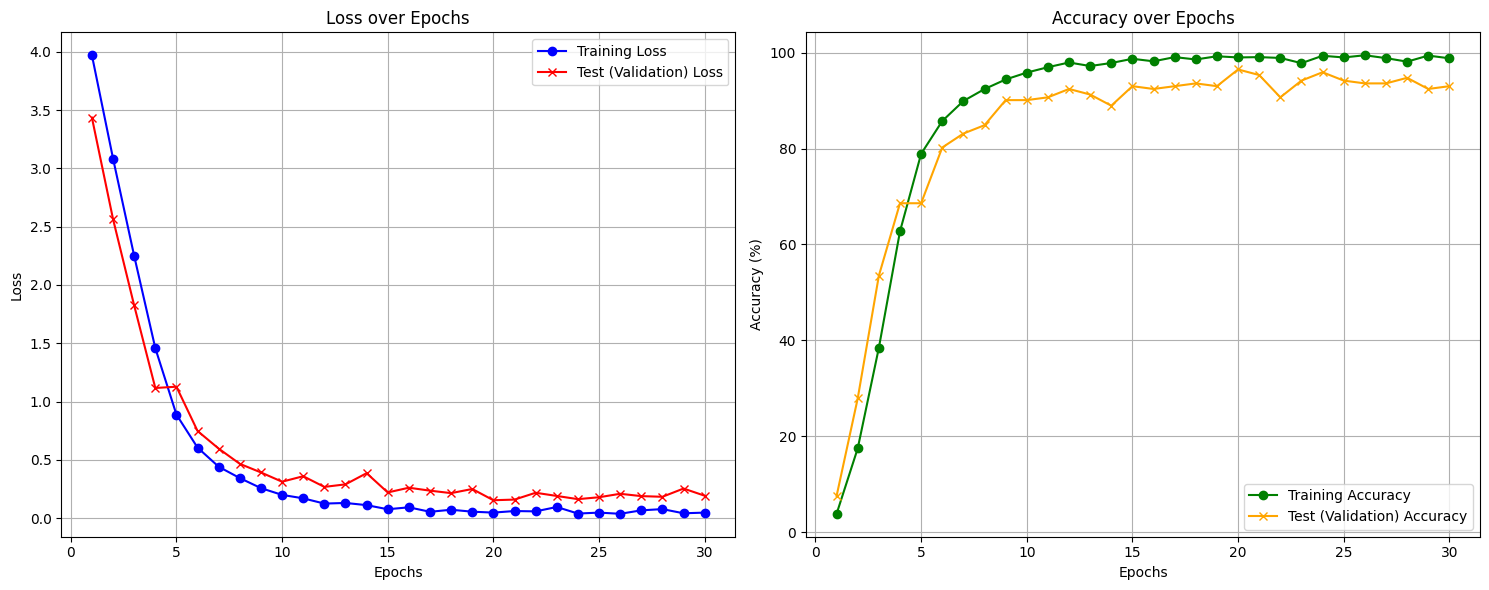

In [ ]:
import matplotlib.pyplot as plt

# PLOT SETTINGS
epochs_range = range(1, num_epochs + 1)

plt.figure(figsize=(15, 6))

# PLOT Loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_losses, label='Training Loss', color='blue', marker='o')
plt.plot(epochs_range, test_losses, label='Test (Validation) Loss', color='red', marker='x')
plt.title('Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# PLOTAccuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_accuracies, label='Training Accuracy', color='green', marker='o')
plt.plot(epochs_range, test_accuracies, label='Test (Validation) Accuracy', color='orange', marker='x')
plt.title('Accuracy over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


## Section 1-4 : training BoTNet model


### first we: the Multi-Head Self-Attention (MHSA) Class

In this section, we define the **`MHSA`** class, which acts as the core component of the **BoTNet** architecture. This module replaces the standard $3 \times 3$ spatial convolutions in the final blocks of the ResNet.

**Key Features of this Implementation:**

* **Relative Position Encoding (2D):** Unlike standard Transformers (like ViT) that often use absolute position embeddings, BoTNet utilizes **Relative Position Encodings**. This allows the model to learn the relative distance between pixels (e.g., "pixel A is 2 steps above pixel B") rather than their absolute coordinates. This is implemented via learnable parameters `rel_h_emb` and `rel_w_emb`.
* **Content + Position Attention:** The attention score is calculated as the sum of content-content interaction ($QK^T$) and content-position interaction ($QR^T$).
* **Visualization Hook:** The class includes a mechanism to store the attention map in `self.last_attn_map`. This is crucial for the later steps where we need to generate heatmaps and perform counterfactual analysis.


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class MHSA(nn.Module):
    def __init__(self, n_dims, width=6, height=12, heads=4):
        super(MHSA, self).__init__()
        self.heads = heads
        self.head_dim = n_dims // heads
        self.scale = self.head_dim ** -0.5

        self.width = width
        self.height = height

        self.query = nn.Conv2d(n_dims, n_dims, kernel_size=1)
        self.key = nn.Conv2d(n_dims, n_dims, kernel_size=1)
        self.value = nn.Conv2d(n_dims, n_dims, kernel_size=1)

        # Relative Position Encoding Definitions
        # we learn an embedding for every possible distance
        # (from negative to positive)
        # number of possible height distances: (2 * height - 1)
        # number of possible width distances: (2 * width - 1)
        self.rel_h_emb = nn.Parameter(torch.randn(2 * height - 1, self.head_dim))
        self.rel_w_emb = nn.Parameter(torch.randn(2 * width - 1, self.head_dim))

        # Normal initialization for better convergence
        nn.init.normal_(self.rel_h_emb, std=0.02)
        nn.init.normal_(self.rel_w_emb, std=0.02)

        self.softmax = nn.Softmax(dim=-1)
        self.last_attn_map = None

    def forward(self, x):
        batch_size, C, H, W = x.size()

        # Generate Q, K, V with shape: (B, heads, N, d) where N = H*W
        q = self.query(x).view(batch_size, self.heads, C // self.heads, -1).permute(0, 1, 3, 2)
        k = self.key(x).view(batch_size, self.heads, C // self.heads, -1).permute(0, 1, 3, 2)
        v = self.value(x).view(batch_size, self.heads, C // self.heads, -1).permute(0, 1, 3, 2)

        # Content-Content Attention (QK^T)
        content_content = torch.matmul(q, k.transpose(-2, -1))

        # Content-Position Attention (QR^T) - The "Relative" Part
        # Calculate relative embeddings for all pixel pairs
        rel_logits = self.get_rel_logits(q, H, W)

        # Summing the two attention parts
        energy = content_content + rel_logits

        # Softmax & Output
        attention = self.softmax(energy * self.scale)
        self.last_attn_map = attention.detach() # save for nextpart

        out = torch.matmul(attention, v)

        # Reshape back to image dimensions
        out = out.permute(0, 1, 3, 2).contiguous().view(batch_size, C, H, W)
        return out

    def get_rel_logits(self, q, H, W):
        # Construct relative indices
        # Using broadcasting, simplicity , speed
        # Relative Height: extracting height embeddings for each pixel relative to others
        # q: (B, heads, HW, d)
        # rel_h_emb: (2H-1, d)

        # Define relative height index matrix
        coords_h = torch.arange(H, device=q.device)
        coords_w = torch.arange(W, device=q.device)

        # Create Meshgrid
        #  want to calculate the row distance of i from row j
        # diff_h[i, j] = i - j + (H - 1) -> Convert to positive index

        # Calculate Height Component
        # q is viewed as (B, heads, H, W, d)
        q_reshaped = q.view(q.size(0), self.heads, H, W, self.head_dim)

        # Calculate Q * R_h^T
        # R_h: (2H-1, d)
        # For every query at position (h_q, w_q), we want to compute its dot product with R_h[h_q - h_k]
        # Optimal BoTNet method (Decomposed):rel_logits_h = q * R_h

        # Simpler matrix method (since 12x6 size is small):
        rel_indices_h = coords_h.view(-1, 1) - coords_h.view(1, -1) + (self.height - 1) # (H, H)
        rel_emb_h = self.rel_h_emb[rel_indices_h] # (H, H, d)

        # Multiply Q by R_h
        # q: (B, heads, H*W, d) -> (B, heads, H, W, d)
        # rel_emb_h expands to match interaction
        # For every pair (i, j) in HW, HW, we only care about their height difference

        # Expand rel_emb_h to (H*W, H*W, d)
        # Row i and column j of the global matrix correspond to pixels (h_i, w_i) and (h_j, w_j)
        # Their vertical distance depends only on h_i and h_j
        rel_emb_h_flat = rel_emb_h.repeat_interleave(W, dim=0).repeat_interleave(W, dim=1) # (HW, HW, d)

        # Same process for Width
        rel_indices_w = coords_w.view(-1, 1) - coords_w.view(1, -1) + (self.width - 1) # (W, W)
        rel_emb_w = self.rel_w_emb[rel_indices_w] # (W, W, d)
        rel_emb_w_flat = rel_emb_w.repeat(H, H, 1) # repeating the blocks (HW, HW, d)

        # Sum relative embeddings of H and W
        rel_emb_total = rel_emb_h_flat + rel_emb_w_flat # (HW, HW, d)

        # Calculate QR^T
        # q: (B, heads, HW, d)
        # rel: (HW, HW, d) -> (1, 1, HW, HW, d)
        # result: (B, heads, HW, HW)

        # b: batch, h: heads, i: query_idx, j: key_idx, d: dim
        rel_logits = torch.einsum('bhid,ijd->bhij', q, rel_emb_total)

        return rel_logits

print("MHSA with STRICT Relative Position Encoding (2D) defined.")


MHSA with STRICT Relative Position Encoding (2D) defined.


### second: BoTNet Bottleneck and Model Builder

 we assemble the complete **BoTNet** architecture by defining two key components:

1.  **`BoTBottleneck` Class:**
    * This class is a modified version of the standard ResNet Bottleneck block.
    * **Crucial Change:** Instead of the standard $3 \times 3$ spatial convolution in the middle of the block, we use the **`MHSA`** layer defined in the previous step.
    * **Structure:** $1 \times 1$ Conv (compress) $\rightarrow$ **MHSA** (spatial mixing) $\rightarrow$ $1 \times 1$ Conv (expand).
    * **Stride Handling:** If the block requires downsampling (stride > 1), we use an Average Pooling layer *before* the MHSA to ensure the feature map dimensions match the expected resolution ($12 \times 6$) for the position encodings.

2.  **`get_botnet50` Function:**
    * This function constructs the full model.
    * It starts with a standard **ResNet50** backbone (without pre-trained weights).
    * It specifically replaces the entire **`layer4`** (the final stage of the network, containing 3 blocks) with our new `BoTBottleneck` blocks.
    * It calculates the specific feature map resolution at `layer4` ($384/32 = 12$, $192/32 = 6$) to initialize the attention layers correctly.


In [ ]:
# the BoTNet class (instead of standard Bottleneck)
class BoTBottleneck(nn.Module):
    expansion = 4

    def __init__(self, inplanes, planes, stride=1, downsample=None, heads=4, resolution=(12, 6)):
        super(BoTBottleneck, self).__init__()

        # 1x1 Conv (chanel reduction)
        self.conv1 = nn.Conv2d(inplanes, planes, kernel_size=1, bias=False)
        self.bn1 = nn.BatchNorm2d(planes)

        # managing Stride:
        # If stride=2 (first block), the image size is halved (e.g., 24x12 -> 12x6).
        # We perform this downsampling BEFORE MHSA to ensure the MHSA input has the correct dimensions (12x6).
        if stride > 1:
            self.downsample_layer = nn.AvgPool2d(kernel_size=(2, 2), stride=stride)
        else:
            self.downsample_layer = nn.Identity()

        # MHSA replaces the 3x3 Conv
        # We pass the exact dimensions (12, 6) so that Position Encoding functions correctly.
        self.mhsa = MHSA(planes, width=resolution[1], height=resolution[0], heads=heads)
        self.bn2 = nn.BatchNorm2d(planes)

        # 1x1 Conv (channel expansion)
        self.conv3 = nn.Conv2d(planes, planes * self.expansion, kernel_size=1, bias=False)
        self.bn3 = nn.BatchNorm2d(planes * self.expansion)

        self.relu = nn.ReLU(inplace=True)
        self.downsample = downsample
        self.stride = stride

    def forward(self, x):
        identity = x

        # 1x1 Conv
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        # MHSA (with potential downsampling)
        out = self.downsample_layer(out)
        out = self.mhsa(out)
        out = self.bn2(out)
        out = self.relu(out)

        # 1x1 Conv
        out = self.conv3(out)
        out = self.bn3(out)

        # Skip Connection
        if self.downsample is not None:
            identity = self.downsample(x)

        out += identity
        out = self.relu(out)

        return out

# the building the BoTNet50 func
def get_botnet50(num_classes, input_resolution=(384, 192)):
    # get the base model with no weights
    model = models.resnet50(weights=None)

    # calculate resolution in layer 4 (divided by  32)
    # 384 / 32 = 12 (Height)
    # 192 / 32 = 6  (Width)
    feat_h, feat_w = input_resolution[0] // 32, input_resolution[1] // 32

    # Layer 4 configuration
    layer4_inplanes = 1024
    planes = 512

    layers = []

    # Block 1 (Downsample Stride 2)
    downsample = nn.Sequential(
        nn.Conv2d(layer4_inplanes, planes * 4, kernel_size=1, stride=2, bias=False),
        nn.BatchNorm2d(planes * 4),
    )
    layers.append(BoTBottleneck(layer4_inplanes, planes, stride=2, downsample=downsample, resolution=(feat_h, feat_w)))

    # Block 2 (Stride 1)
    layers.append(BoTBottleneck(planes * 4, planes, resolution=(feat_h, feat_w)))

    # Block 3 (Stride 1)
    layers.append(BoTBottleneck(planes * 4, planes, resolution=(feat_h, feat_w)))

    # total replacement of layer4 of the original model
    model.layer4 = nn.Sequential(*layers)

    # change the last layer(FC)
    model.fc = nn.Linear(model.fc.in_features, num_classes)

    return model

print("BoTNet architecture defined successfully.")


BoTNet architecture defined successfully.


### third : Initialize, Verify, and Train BoTNet

Now that the architecture components are defined, we proceed to instantiation and training. This block performs three key tasks:

1.  **Model Initialization:** Creates the `BoTNet50` model instance and moves it to the GPU.
2.  **Structure Verification:** Prints the structure of **`layer4`** to confirm that the standard bottlenecks have been successfully replaced by our custom `BoTBottleneck` blocks containing the `MHSA` layers.
3.  **Training Loop:** Trains the model from scratch for 30 epochs, tracking loss and accuracy for both training and validation sets to evaluate performance.


In [ ]:
import time

#  INITIALIZE MODEL
# make a model of BoTNet
bot_model = get_botnet50(num_classes=len(unique_classes)).to(device)

# loss function an doptimizer
criterion = nn.CrossEntropyLoss()
optimizer_bot = torch.optim.Adam(bot_model.parameters(), lr=0.0001)

#  PRINT STRUCTURE
# getting an output of the model structure and the layers of it
print("\n" + "="*40)
print("BoTNet Layer 4 Structure (MHSA Verification):")
print("="*40)
# only print layer 4  for the main change is there
print(bot_model.layer4)
print("\n" + "="*40)

# TRAIN BOTNET (30 Epochs)
num_epochs = 30
bot_train_losses, bot_test_losses = [], []
bot_train_accuracies, bot_test_accuracies = [], []

print(f"--- Starting BoTNet Training for {num_epochs} Epochs ---")

for epoch in range(num_epochs):
    start_time = time.time()

    # TRAIN PHASE
    bot_model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer_bot.zero_grad()

        outputs = bot_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer_bot.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / total_train
    epoch_train_acc = 100 * correct_train / total_train

    # TEST PHASE
    bot_model.eval()
    running_test_loss = 0.0
    correct_test = 0
    total_test = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = bot_model(images)
            loss = criterion(outputs, labels)

            running_test_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total_test += labels.size(0)
            correct_test += (predicted == labels).sum().item()

    epoch_test_loss = running_test_loss / total_test
    epoch_test_acc = 100 * correct_test / total_test

    # Save history
    bot_train_losses.append(epoch_train_loss)
    bot_test_losses.append(epoch_test_loss)
    bot_train_accuracies.append(epoch_train_acc)
    bot_test_accuracies.append(epoch_test_acc)

    duration = time.time() - start_time
    print(f"Epoch [{epoch+1}/{num_epochs}] | Time: {duration:.0f}s")
    print(f"   Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}%")
    print(f"   Test  Loss: {epoch_test_loss:.4f} | Test  Acc: {epoch_test_acc:.2f}%")

print("--- BoTNet Training Complete ---")



BoTNet Layer 4 Structure (MHSA Verification):
Sequential(
  (0): BoTBottleneck(
    (conv1): Conv2d(1024, 512, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (downsample_layer): AvgPool2d(kernel_size=(2, 2), stride=2, padding=0)
    (mhsa): MHSA(
      (query): Conv2d(512, 512, kernel_size=(1, 1), stride=(1, 1))
      (key): Conv2d(512, 512, kernel_size=(1, 1), stride=(1, 1))
      (value): Conv2d(512, 512, kernel_size=(1, 1), stride=(1, 1))
      (softmax): Softmax(dim=-1)
    )
    (bn2): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (conv3): Conv2d(512, 2048, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn3): BatchNorm2d(2048, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (downsample): Sequential(
      (0): Conv2d(1024, 2048, kernel_size=(1, 1), stride=(2, 2), bias=False)
      (1): BatchN

the report required a specific model structure print , so here we provide it :


In [ ]:
#  PRINT STRUCTURE
print("\n" + "="*40)
print("FULL BoTNet50 Structure (Assignment Requirement):")
print("="*40)

# Print the entire model (as required by the assignment, the output must be visible in the code)
print(bot_model)

print("\n" + "="*40)
print("Focus on Layer 4 (The Changed Part):")
print("="*40)

# Specifically print Layer 4 for easier analysis in the report
print(bot_model.layer4)
print("\n" + "="*40)

# Verify if the attention map storage capability is active (Requirement: save attention layer output).
# We have implemented 'self.last_attn_map' in the MHSA class.
# Printing a confirmation message to ensure this requirement is acknowledged.
print("Check: Attention Map storage mechanism is implemented in MHSA class via 'self.last_attn_map'.")



FULL BoTNet50 Structure (Assignment Requirement):
ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (

## Section 1-5: Attention Heatmap Generation

we visualize "what the model sees" by extracting and displaying the attention maps. To answer the assignment question, we perform three key steps:

1.  **Extract Heatmap:** We use a **Hook** to capture the output of the final **MHSA** layer during the forward pass.
2.  **Un-normalize:** We convert the input tensors back into viewable RGB images by reversing the normalization process.
3.  **Overlay:** We compute the "activation energy" (mean of absolute values) from the attention layer, normalize it, and overlay it as a heatmap on the original image. This reveals whether the model is focusing on the cow's skin patterns or irrelevant background features.


Hook registered!


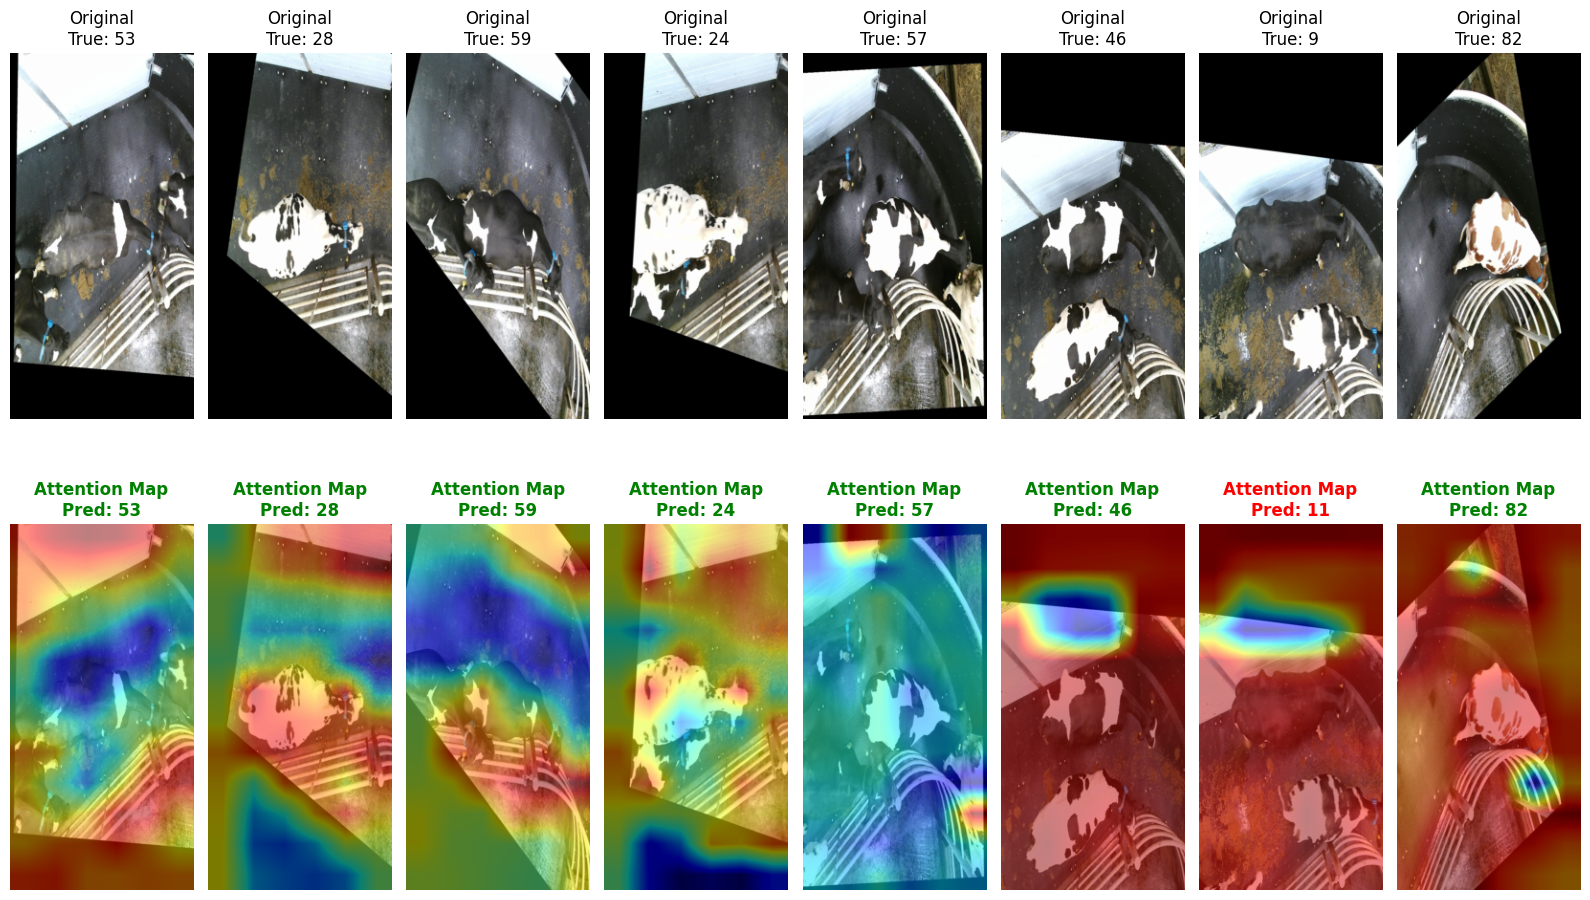

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch

# Helper function to Unnormalize
def unnormalize(tensor, mean, std):
    tensor = tensor.clone().detach().cpu()
    for t, m, s in zip(tensor, mean, std):
        t.mul_(s).add_(m)
    img = tensor.permute(1, 2, 0).numpy()
    return np.clip(img, 0, 1)

# Hook
# Variable to store the output of the attention layer
activation = {}
def get_activation(name):
    def hook(model, input, output):
        activation[name] = output.detach()
    return hook

# Registering the hook (using try-except to handle re-execution errors)
try:
    # Hook to the last MHSA layer
    bot_model.layer4[2].mhsa.register_forward_hook(get_activation('last_mhsa'))
    print("Hook registered!")
except:
    print("Hook already registered or error.")

#Generating and Displaying the Heatmap
bot_model.eval()

# get a batch of data
images, labels = next(iter(test_loader))
images = images.to(device)

# go through the model
outputs = bot_model(images)
_, preds = torch.max(outputs, 1)

# Output of the attention layer [32, 512, 12, 6]
attn_output = activation['last_mhsa']

num_show = 8
plt.figure(figsize=(16, 10))

for i in range(num_show):
    # Original Image
    original_img = unnormalize(images[i], mean_stats, std_stats)

    # create Heatmap
    # Instead of a simple mean, we use the mean of absolute values
    # This indicates the "intensity" of the activity, not its direction
    feature_map = attn_output[i] # [512, 12, 6]

    # calculate Activation Energy
    # Mean Absolute Value (L1 Norm) -> Recommended
    heatmap = torch.mean(torch.abs(feature_map), dim=0).cpu().numpy()

    # or we could use Power of 2 (L2 Norm) -> Increases contrast significantly
    # heatmap = torch.mean(torch.pow(feature_map, 2), dim=0).cpu().numpy()

    # Precise normalization between 0 and 1
    # This line ensures there is at least one red point (1.0) in the image
    heatmap = np.maximum(heatmap, 0)
    if np.max(heatmap) != np.min(heatmap):
        heatmap = (heatmap - np.min(heatmap)) / (np.max(heatmap) - np.min(heatmap))
    else:
        heatmap = np.zeros_like(heatmap)


    # Resize to match original image dimensions
    heatmap_resized = cv2.resize(heatmap, (original_img.shape[1], original_img.shape[0]))

    # Coloring (Blue=0, Red=1)
    heatmap_colored = plt.cm.jet(heatmap_resized)[:, :, :3]

    # Overlay
    # Slightly reduced heatmap transparency so the cow is more visible
    superimposed_img = heatmap_colored * 0.5 + original_img * 0.5

    # Display
    ax = plt.subplot(2, num_show, i + 1)
    plt.imshow(original_img)
    t_lbl = unique_classes[labels[i].item()]
    plt.title(f"Original\nTrue: {t_lbl}")
    plt.axis('off')

    ax = plt.subplot(2, num_show, i + 1 + num_show)
    plt.imshow(superimposed_img)
    p_lbl = unique_classes[preds[i].item()]

    col = 'green' if preds[i] == labels[i] else 'red'
    plt.title(f"Attention Map\nPred: {p_lbl}", color=col, fontsize=12, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.show()


## Sction 1-7) ploting and result analysis



This cell does:

  a. plot Loss/Accuracy curve for BoTNet

  b. plot Loss/Accuracy curve for comparing (ResNet vs BoTNet)



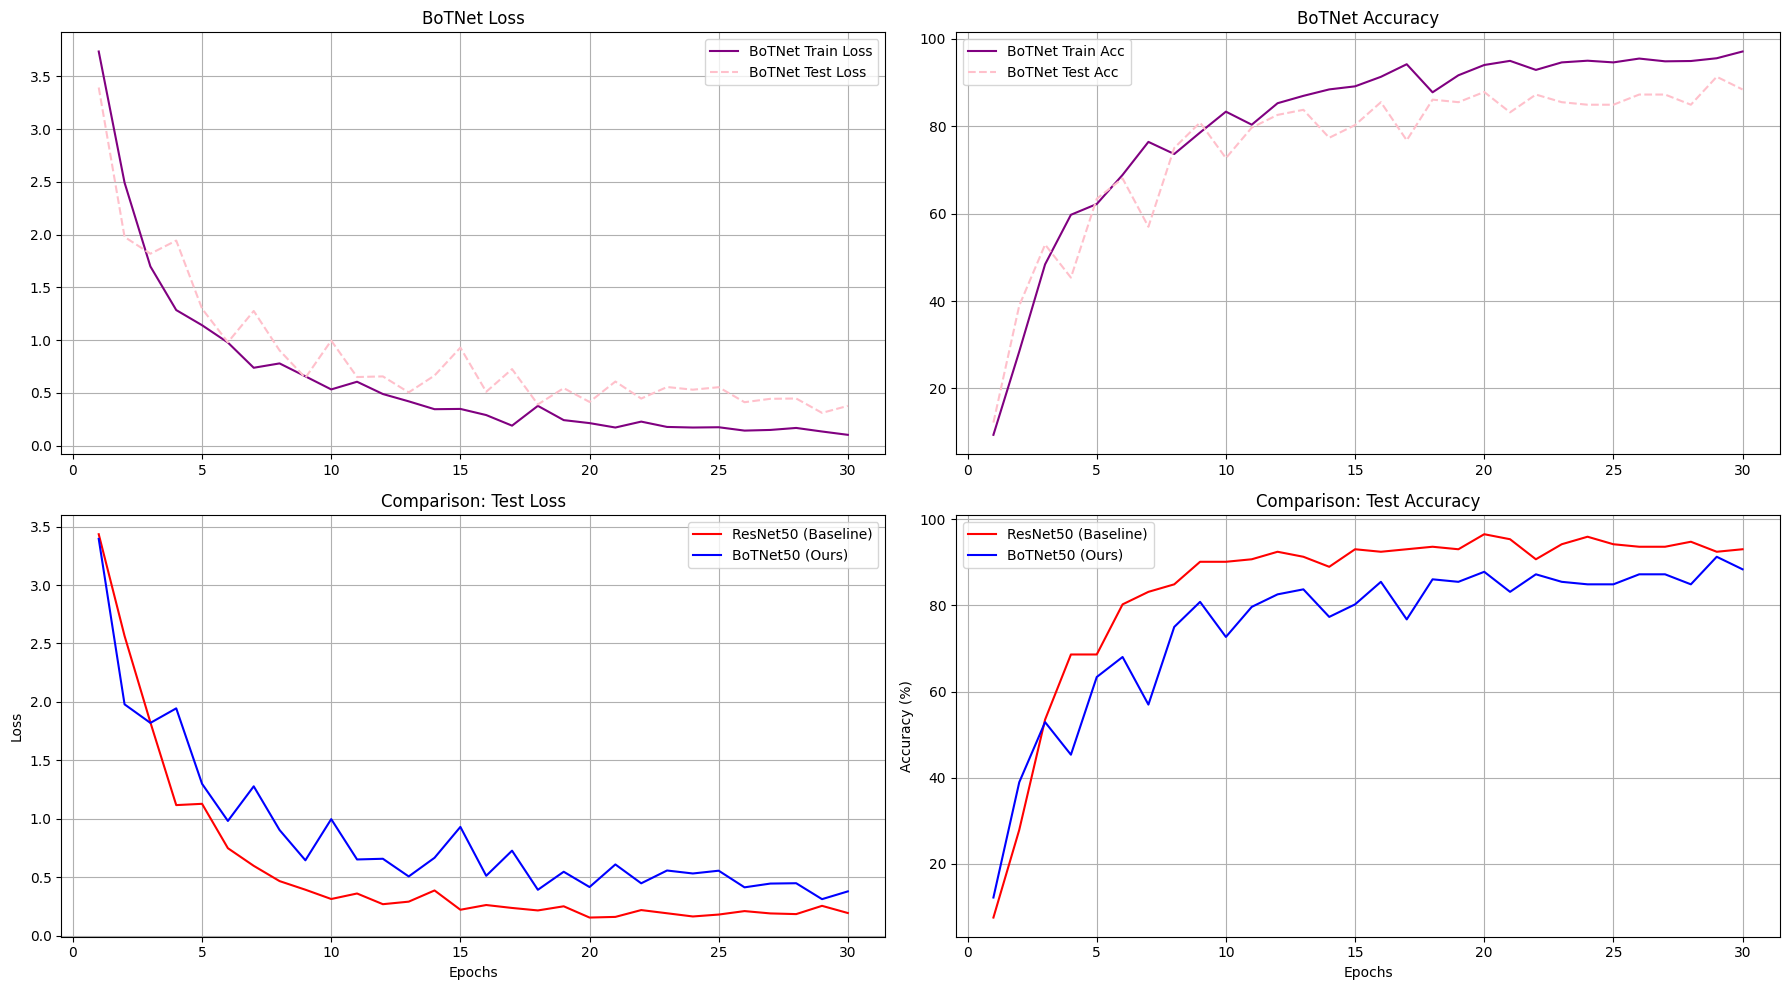

In [ ]:
import matplotlib.pyplot as plt

epochs_range = range(1, num_epochs + 1)

plt.figure(figsize=(18, 10))

# only BoTNet plots
plt.subplot(2, 2, 1)
plt.plot(epochs_range, bot_train_losses, label='BoTNet Train Loss', color='purple')
plt.plot(epochs_range, bot_test_losses, label='BoTNet Test Loss', color='pink', linestyle='--')
plt.title('BoTNet Loss')
plt.legend()
plt.grid(True)

plt.subplot(2, 2, 2)
plt.plot(epochs_range, bot_train_accuracies, label='BoTNet Train Acc', color='purple')
plt.plot(epochs_range, bot_test_accuracies, label='BoTNet Test Acc', color='pink', linestyle='--')
plt.title('BoTNet Accuracy')
plt.legend()
plt.grid(True)

# the comparitive plot (ResNet vs BoTNet)
# for part 1-7) analys the results
plt.subplot(2, 2, 3)
plt.plot(epochs_range, test_losses, label='ResNet50 (Baseline)', color='red')
plt.plot(epochs_range, bot_test_losses, label='BoTNet50 (Ours)', color='blue')
plt.title('Comparison: Test Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(2, 2, 4)
plt.plot(epochs_range, test_accuracies, label='ResNet50 (Baseline)', color='red')
plt.plot(epochs_range, bot_test_accuracies, label='BoTNet50 (Ours)', color='blue')
plt.title('Comparison: Test Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


## Impact of Class Imbalance & Per-Class Accuracy Analysis

To address the assignment question regarding **significant differences** between the models and the **impact of imbalance**, we cannot rely solely on global accuracy.




we perform a granular analysis:
1.  **Per-Class Accuracy:** We calculate accuracy for each specific cow ID independently.
2.  **Minority vs. Majority Analysis:** Since our test set remains imbalanced (reflecting the real distribution), we sort classes by their original sample count to compare performance on "rare" vs. "common" cows.
3.  **Visualization:** We plot the relationship between *Class Size* and *Test Accuracy* to determine if BoTNet offers better generalization for under-represented classes compared to ResNet.


Calculating per-class accuracy for ResNet...
Calculating per-class accuracy for BoTNet...

--- low datasamples data analysis (Minority Classes) ---
Class ID   | Org Count  | ResNet Acc   | BoTNet Acc  
--------------------------------------------------
7          | 5          | 0.0%       | 100.0%
29         | 5          | 0.0%       | 0.0%
28         | 5          | 100.0%       | 100.0%
51         | 5          | 100.0%       | 100.0%
78         | 5          | 100.0%       | 100.0%
88         | 5          | 100.0%       | 100.0%
24         | 6          | 100.0%       | 100.0%
20         | 6          | 100.0%       | 100.0%
58         | 6          | 100.0%       | 100.0%
27         | 6          | 100.0%       | 100.0%

--- hight datasamples data analysis (Majority Classes) ---
82         | 49         | 90.0%       | 90.0%
10         | 47         | 88.9%       | 77.8%
9          | 43         | 100.0%       | 88.9%
34         | 41         | 87.5%       | 87.5%
45         | 38         | 87

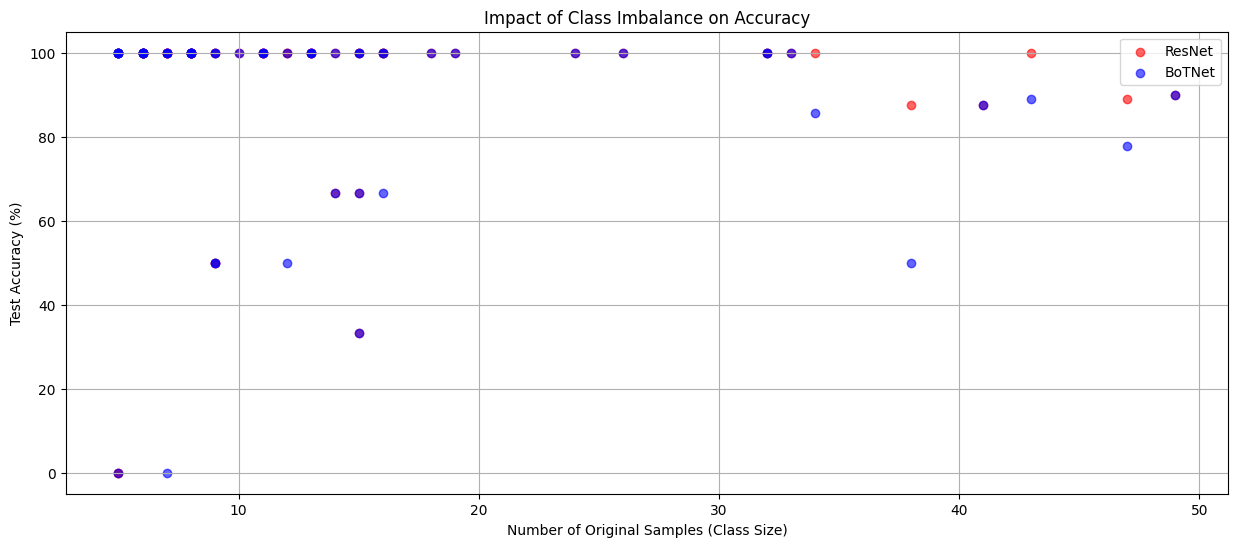

In [ ]:
# accuracy computations for each class
import numpy as np

def get_accuracy_per_class(model, loader, num_classes):
    model.eval()
    class_correct = list(0. for i in range(num_classes))
    class_total = list(0. for i in range(num_classes))

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            c = (predicted == labels).squeeze()

            for i in range(len(labels)):
                label = labels[i].item()
                class_correct[label] += c[i].item()
                class_total[label] += 1

    return class_correct, class_total

# get the info for both models
print("Calculating per-class accuracy for ResNet...")
resnet_correct, resnet_total = get_accuracy_per_class(model, test_loader, len(unique_classes))

print("Calculating per-class accuracy for BoTNet...")
bot_correct, bot_total = get_accuracy_per_class(bot_model, test_loader, len(unique_classes))

# the relationship between "Sample Count" and "Accuracy"
# We retrieve the original sample counts for each class from the final_class_counts dictionary.
# We must sort them based on their numerical labels (0, 1, 2...).
original_counts = []
for i in range(len(unique_classes)):
    label_str = unique_classes[i]
    count = final_class_counts[label_str]
    original_counts.append(count)

# accuracy calc
resnet_accs = [c/t * 100 if t>0 else 0 for c, t in zip(resnet_correct, resnet_total)]
bot_accs = [c/t * 100 if t>0 else 0 for c, t in zip(bot_correct, bot_total)]

# plot comparing plots
plt.figure(figsize=(15, 6))

# orginizing based on data samples (accending) to see the possible pattern
sorted_indices = np.argsort(original_counts)
sorted_counts = np.array(original_counts)[sorted_indices]
sorted_resnet = np.array(resnet_accs)[sorted_indices]
sorted_bot = np.array(resnet_accs)[sorted_indices]

# show 5 classes with the most and 5 classes with the least number of data samples
print("\n--- low datasamples data analysis (Minority Classes) ---")
print(f"{'Class ID':<10} | {'Org Count':<10} | {'ResNet Acc':<12} | {'BoTNet Acc':<12}")
print("-" * 50)
for i in range(10): # 10 first of the least
    idx = sorted_indices[i]
    print(f"{unique_classes[idx]:<10} | {original_counts[idx]:<10} | {resnet_accs[idx]:.1f}%       | {bot_accs[idx]:.1f}%")

print("\n--- hight datasamples data analysis (Majority Classes) ---")
for i in range(1, 6): # 5 last
    idx = sorted_indices[-i]
    print(f"{unique_classes[idx]:<10} | {original_counts[idx]:<10} | {resnet_accs[idx]:.1f}%       | {bot_accs[idx]:.1f}%")

# Scatter Plot
plt.scatter(original_counts, resnet_accs, color='red', alpha=0.6, label='ResNet')
plt.scatter(original_counts, bot_accs, color='blue', alpha=0.6, label='BoTNet')
plt.xlabel('Number of Original Samples (Class Size)')
plt.ylabel('Test Accuracy (%)')
plt.title('Impact of Class Imbalance on Accuracy')
plt.legend()
plt.grid(True)
plt.show()
